# **Análise Exploratória de Risco de Crédito**

In [15]:
# impoertando bibliotecas
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

In [4]:
# carregando o dataset
df = pd.read_csv('../data/cr_loan.csv')

# olhando as estruturas do dataset
df.dtypes

person_age                      int64
person_income                   int64
person_home_ownership             str
person_emp_length             float64
loan_intent                       str
loan_grade                        str
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file         str
cb_person_cred_hist_length      int64
dtype: object

In [5]:
# visualizando as primeiras linhas do dataset
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


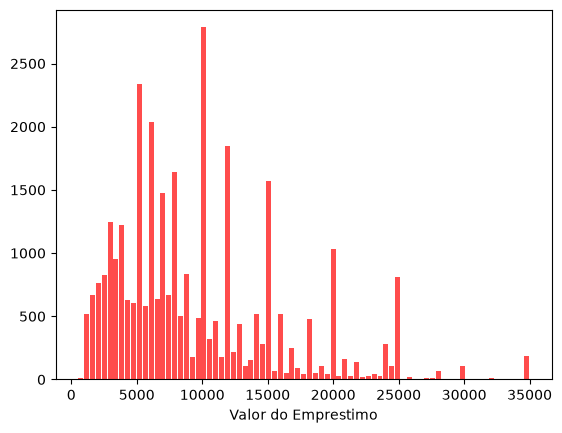

In [8]:
# vendo a distribuição dos valores de emprestimo
n, bins, patches = plt.hist(df['loan_amnt'], bins="auto", color='red', alpha=0.7, rwidth=0.85)
plt.xlabel('Valor do Emprestimo')
plt.show()

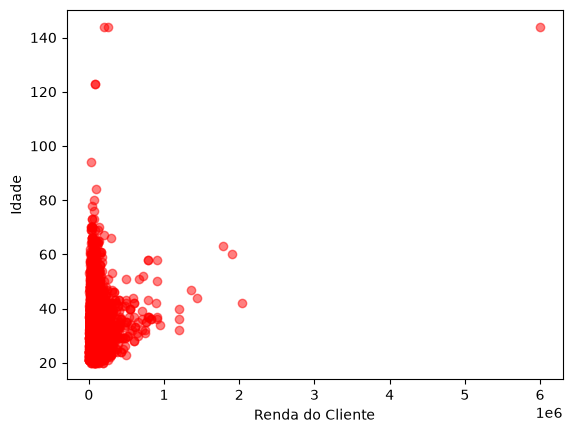

In [10]:
# Verificando a dispersão de renda em função da idade do cliente
plt.scatter(df["person_income"], df["person_age"], alpha=0.5, color="red")
plt.xlabel("Renda do Cliente")
plt.ylabel("Idade")
plt.show()

In [11]:
# crosstab entre o finalidade do emprestimo e o status do emprestimo
print(pd.crosstab(df['loan_intent'] ,df['loan_status'], margins=True))


loan_status            0     1    All
loan_intent                          
DEBTCONSOLIDATION   3722  1490   5212
EDUCATION           5342  1111   6453
HOMEIMPROVEMENT     2664   941   3605
MEDICAL             4450  1621   6071
PERSONAL            4423  1098   5521
VENTURE             4872   847   5719
All                25473  7108  32581


In [ ]:
# Distribuição da inadimplência por nível de risco e situação de moradia
pd.crosstab(df['person_home_ownership'], [df['loan_status'], df["loan_grade"]])

loan_status               0                                 1             \
loan_grade                A     B     C    D    E   F  G    A     B    C   
person_home_ownership                                                      
MORTGAGE               5219  3729  1934  658  178  36  0  239   324  321   
OTHER                    23    29    11    9    2   0  0    3     5    6   
OWN                     860   770   464  264   26   7  0   66    34   31   
RENT                   3602  4222  2710  554  137  28  1  765  1338  981   

loan_status                               
loan_grade                D    E   F   G  
person_home_ownership                     
MORTGAGE                553  161  61  31  
OTHER                    11    6   2   0  
OWN                      18   31   8   5  
RENT                   1559  423  99  27

In [18]:
# Média de comprometimento da renda por tipo de moradia e status do empréstimo
pd.crosstab(df["person_home_ownership"], df["loan_status"], values=df["loan_percent_income"], aggfunc="mean")

loan_status,0,1
person_home_ownership,,
MORTGAGE,0.146504,0.184882
OTHER,0.143784,0.300000
OWN,0.180013,0.297358
RENT,0.144611,0.264859


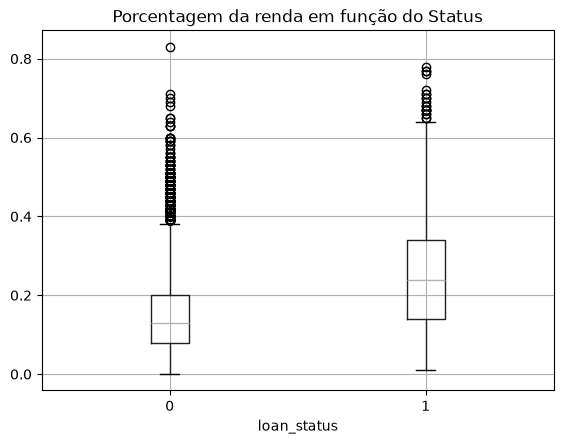

In [24]:
# boxplot da porcentagem da renda em função do status do emprestimo

df.boxplot(column = ["loan_percent_income"], by = "loan_status")
plt.title("Porcentagem da renda em função do Status")
plt.suptitle("")
plt.show()